# Is the new alignment objectively better? — IoU of the pad masks

**Question.** The new `align-plates` tool *looks* better than the previous
per-cell crops: no empty rows, no crops of bare silicon. But "looks better" is
not a number. This notebook scores both with the same metric: for each cell,
the **intersection-over-union** of the pad as seen in the photo crop and the pad
as seen in the height-map crop.

**Why IoU.** It is the standard way to ask "do these two outlines agree?" —
used to compare a predicted box with a ground-truth box, or two annotators'
labels. Here the two outlines are the same physical pad drawn by two
instruments; if the crops are aligned, the outlines sit on top of each other.
IoU = 1 means identical; 0 means no overlap at all.

**How the comparison is kept fair.** Each method contributes only *where it says
the cell is* — one point in the photo, one point in the height map. Everything
else is identical: the same physical window (0.9 × pitch ≈ 240 µm) is cut from
both instruments, the same rule makes the pad mask (half-max threshold,
component nearest the centre, holes filled), and photo pixels are converted to
micrometres with the per-plate scale so both masks share one frame.

* **previous crops** — the stored centroids that produced the earlier training
  set (`data/metadata/*_crop_details*.json`). Their height-map coordinates are
  in a rotated, resampled space, so a per-plate affine (fit on the cells the
  pipeline got right, robustly) converts them to µm.
* **align-plates** — the lattice slot and its image under the fitted
  photo→scan affine. This is exactly what the tool writes to disk.
* **align-plates + detected centres** — the same registration, but each crop
  is centred on the pad the detector actually found in that slot, falling back
  to the lattice when no detection was assigned. Reported because the first
  pass showed it is where the remaining headroom is.

Cells with no pad in the scan or in the photo (chipped off, never printed) are
excluded for every method. Cells a method *failed to find* count as IoU 0 —
that is a method failure, not a missing pad.

In [1]:
import csv, sys
from pathlib import Path
from collections import defaultdict
import numpy as np
from IPython.display import Image, display

STUDY = Path.cwd() if (Path.cwd() / "results").exists() else Path("studies/03-alignment-iou")
sys.path.insert(0, str(STUDY / "src"))
import iou_lib as L

def read(name):
    with (STUDY / "results" / name).open() as f:
        return list(csv.DictReader(f))

cells, plates, summary, conv = (read(n) for n in ("cells.csv", "plates.csv", "summary.csv", "unit_conversion.csv"))
scored = [c for c in cells if c["status"] != "excluded_missing"]
print(f"{len({c['plate'] for c in cells})} plates · {len(scored)//3} cells with a pad in both instruments · "
      f"{(len(cells)-len(scored))//3} excluded as missing")

45 plates · 2855 cells with a pad in both instruments · 25 excluded as missing


## 1. The headline table

In [2]:
hdr = f"{'method':36} {'mean':>6} {'median':>7} {'zero':>7} {'<0.3':>7} {'failures':>9} {'ceiling':>8} {'offset':>8}"
print(hdr); print("-" * len(hdr))
for s in summary:
    print(f"{s['label']:36} {float(s['mean_iou']):6.3f} {float(s['median_iou']):7.3f} "
          f"{float(s['frac_iou_zero'])*100:6.1f}% {float(s['frac_iou_below_0p3'])*100:6.1f}% "
          f"{int(s['n_failures']):9d} {float(s['mean_ceiling_iou']):8.3f} {float(s['median_offset_um']):6.1f} µm")
print()
print("ceiling = IoU the two masks would reach if their centroids coincided (shape disagreement between the instruments)")
print("offset  = median distance between the photo-pad and height-pad centroids, µm, over cells where both were found")

method                                 mean  median    zero    <0.3  failures  ceiling   offset
-----------------------------------------------------------------------------------------------
previous crops                        0.669   0.722    2.6%    3.7%        59    0.727    4.4 µm
align-plates, lattice slots only (as shipped 2026-10-08)  0.634   0.657    0.1%    1.8%         0    0.729    7.4 µm
align-plates (detected centres, current default)  0.709   0.750    0.1%    0.9%         0    0.729    2.5 µm

ceiling = IoU the two masks would reach if their centroids coincided (shape disagreement between the instruments)
offset  = median distance between the photo-pad and height-pad centroids, µm, over cells where both were found


## 2. The picture

Panel A is the distribution over every cell. Panel B compares the two methods
plate by plate — a point above the dotted line is a plate where the new tool
scores higher. Panel C counts the ways a crop can be wrong. Panel D is the
decoder ring: what a given IoU corresponds to in micrometres of misalignment
for a pad-sized rectangle, with the measured cells scattered on top.

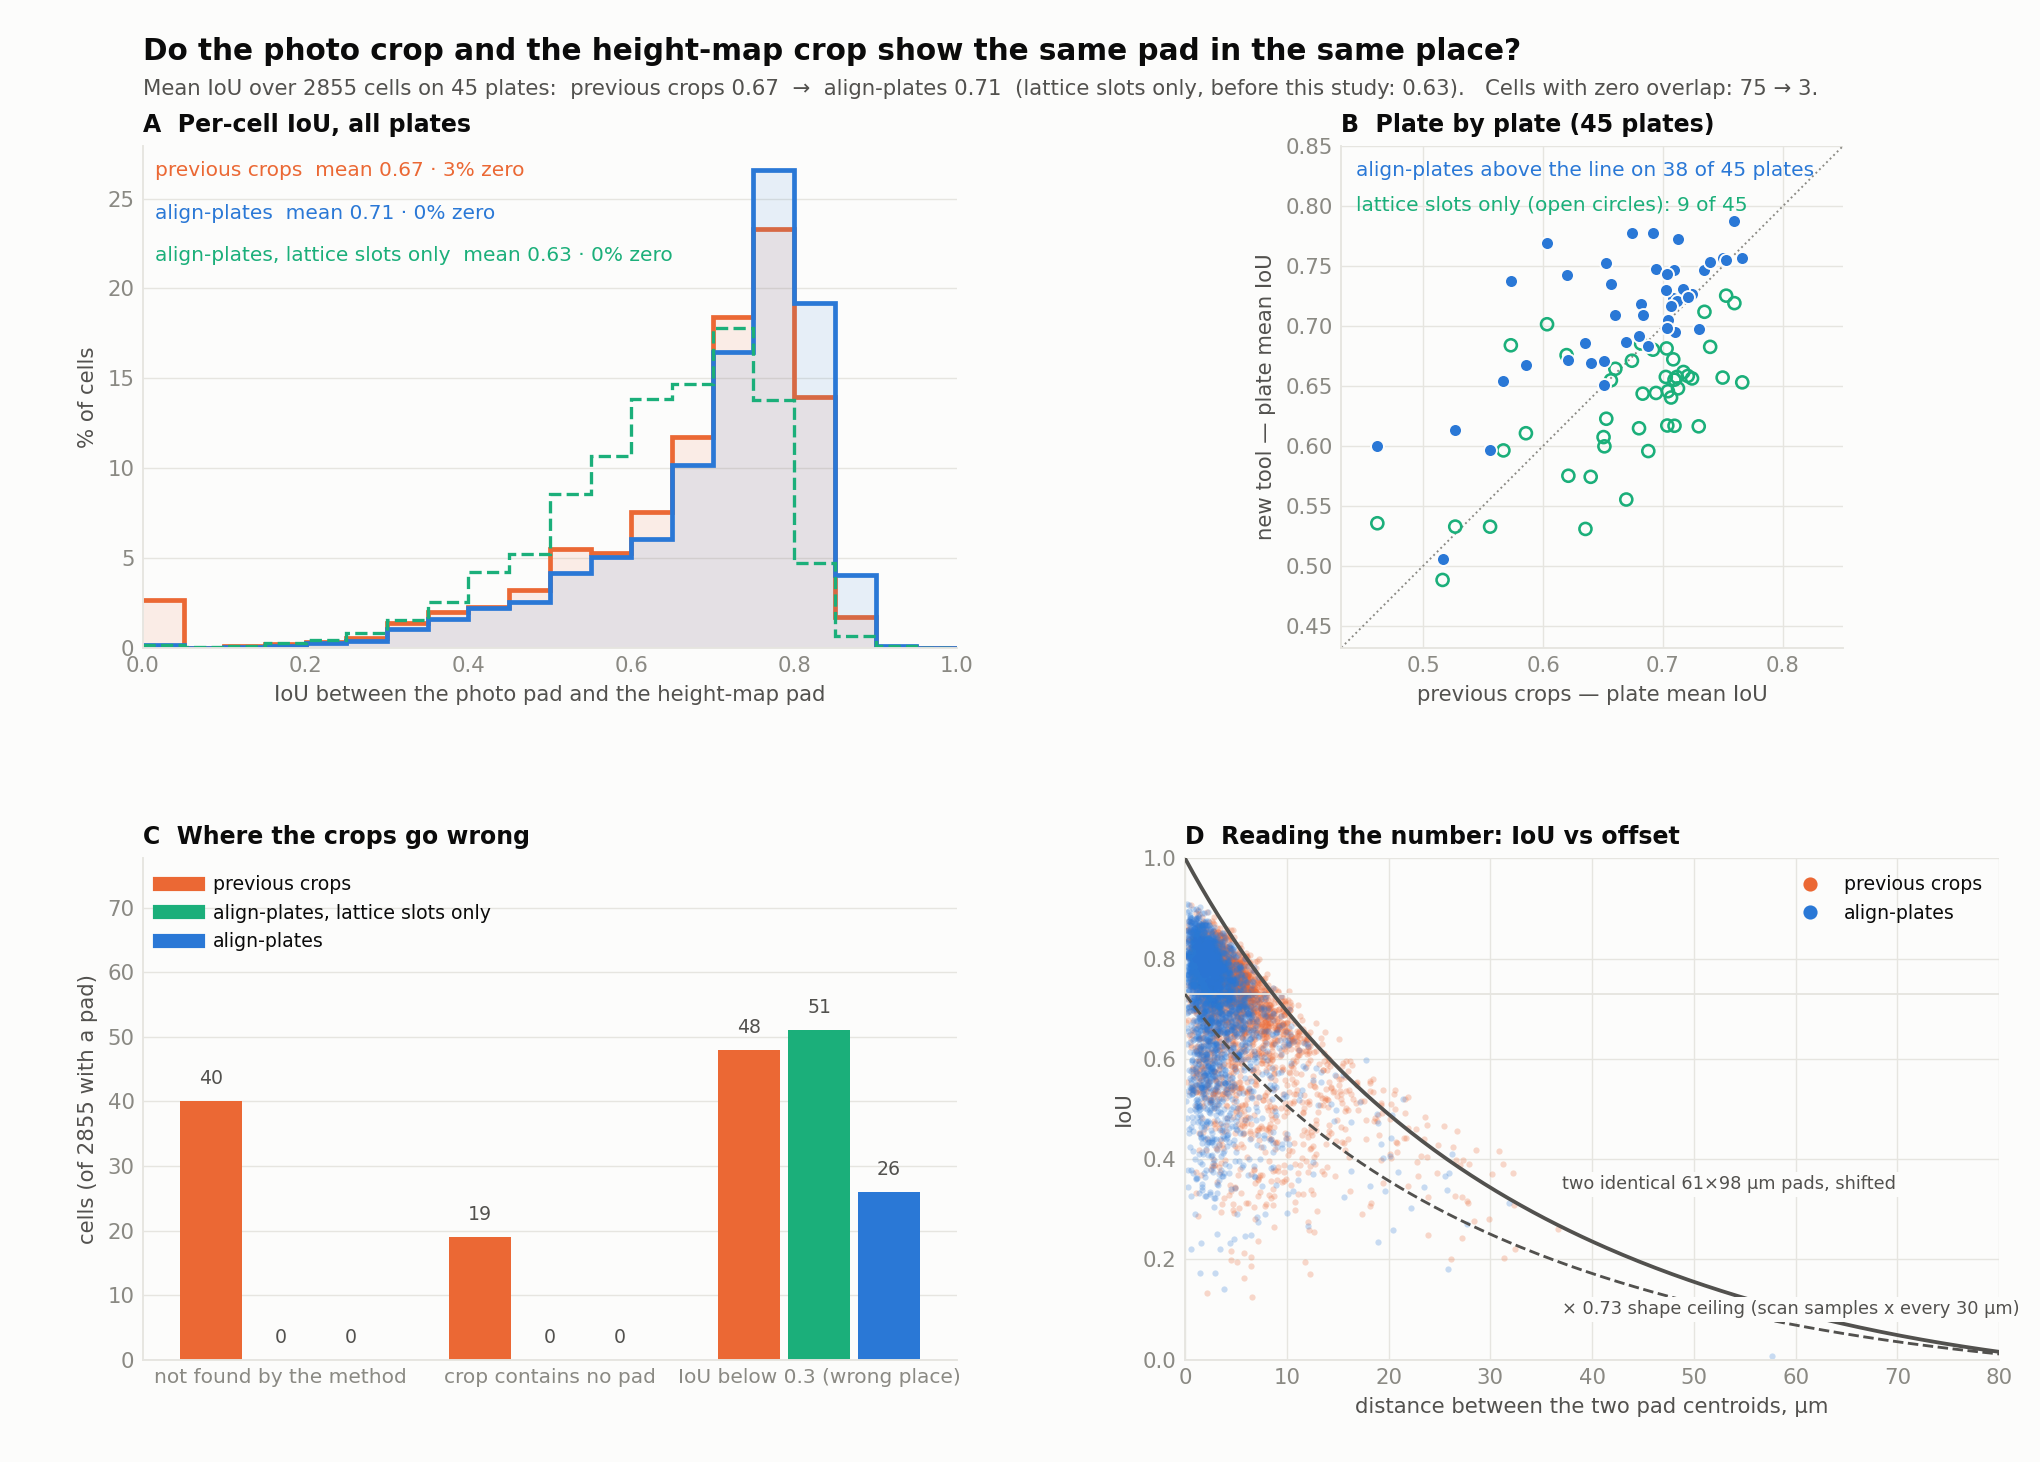

In [3]:
display(Image(str(STUDY / "figures" / "iou_summary.png"), width=1000))

## 3. The same cells under both methods

Left block: previous crops. Right block: `align-plates`. Outlines are the pad
masks; in the overlay, dark is where both instruments agree the pad is, orange
tint is photo-only, blue tint is height-map-only.

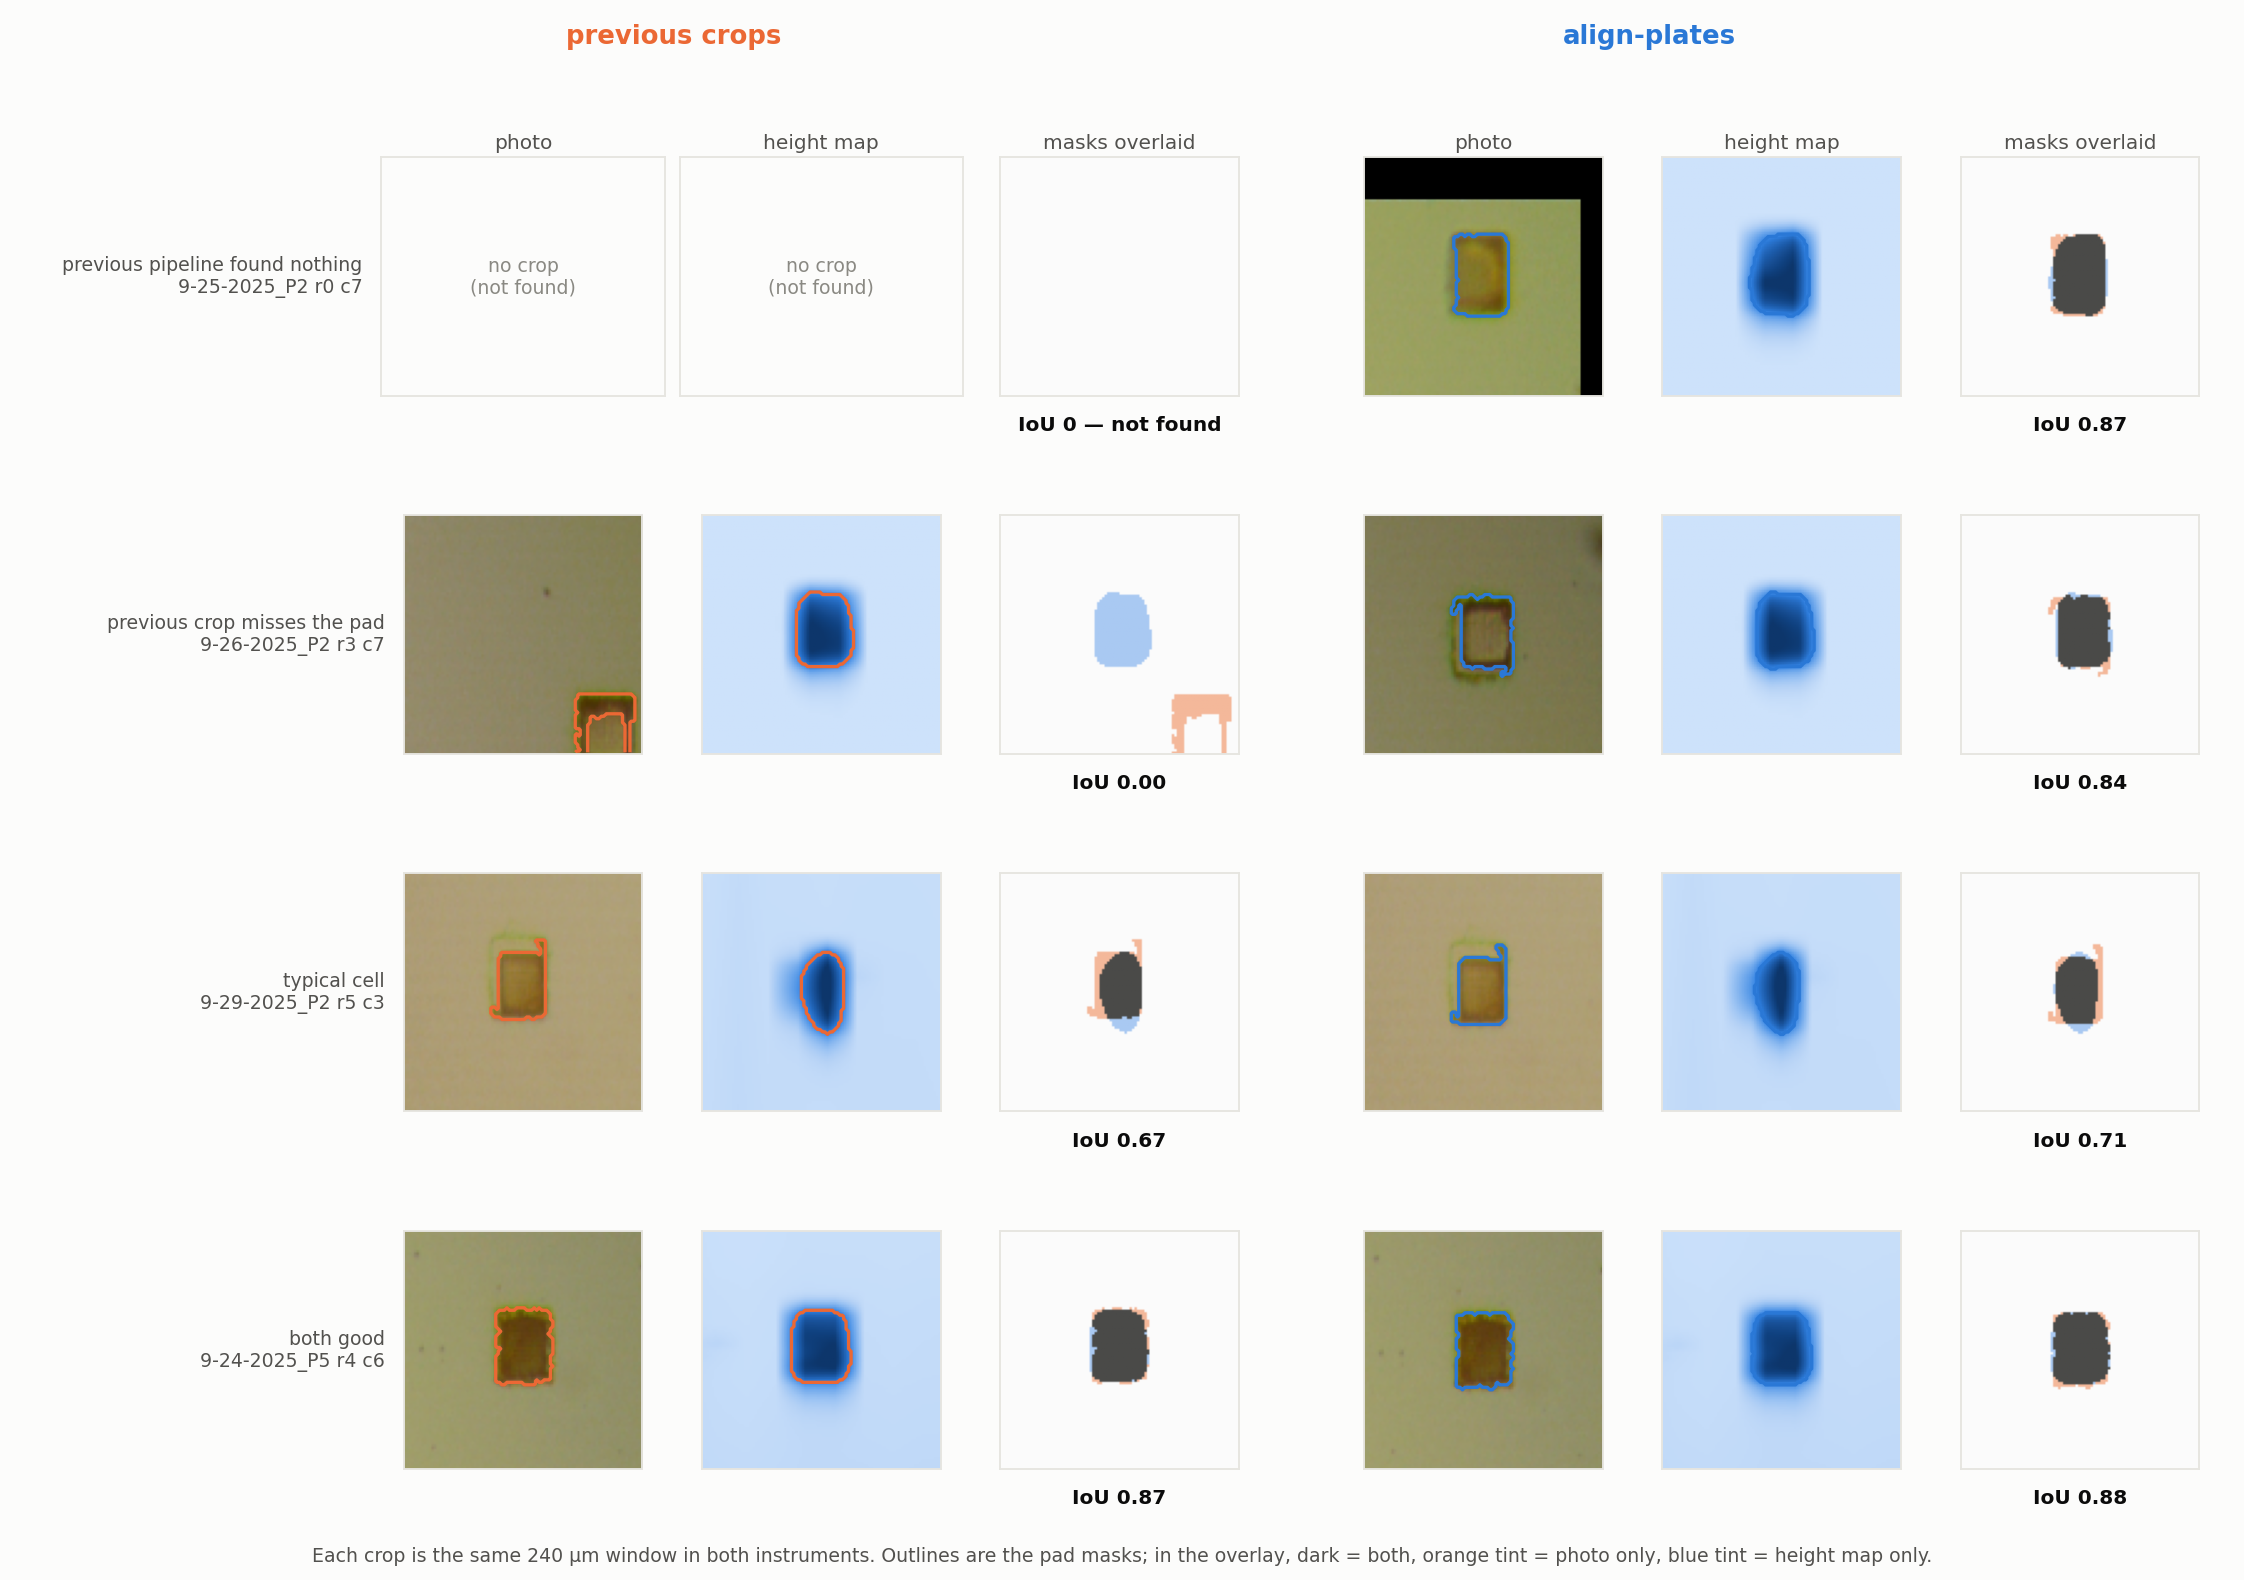

In [4]:
display(Image(str(STUDY / "figures" / "iou_examples.png"), width=1000))

## 4. Whole plates at a glance

The plate where the previous crops did worst, and the one where they did best.
An empty row in the earlier crops shows up as a row of zeros.

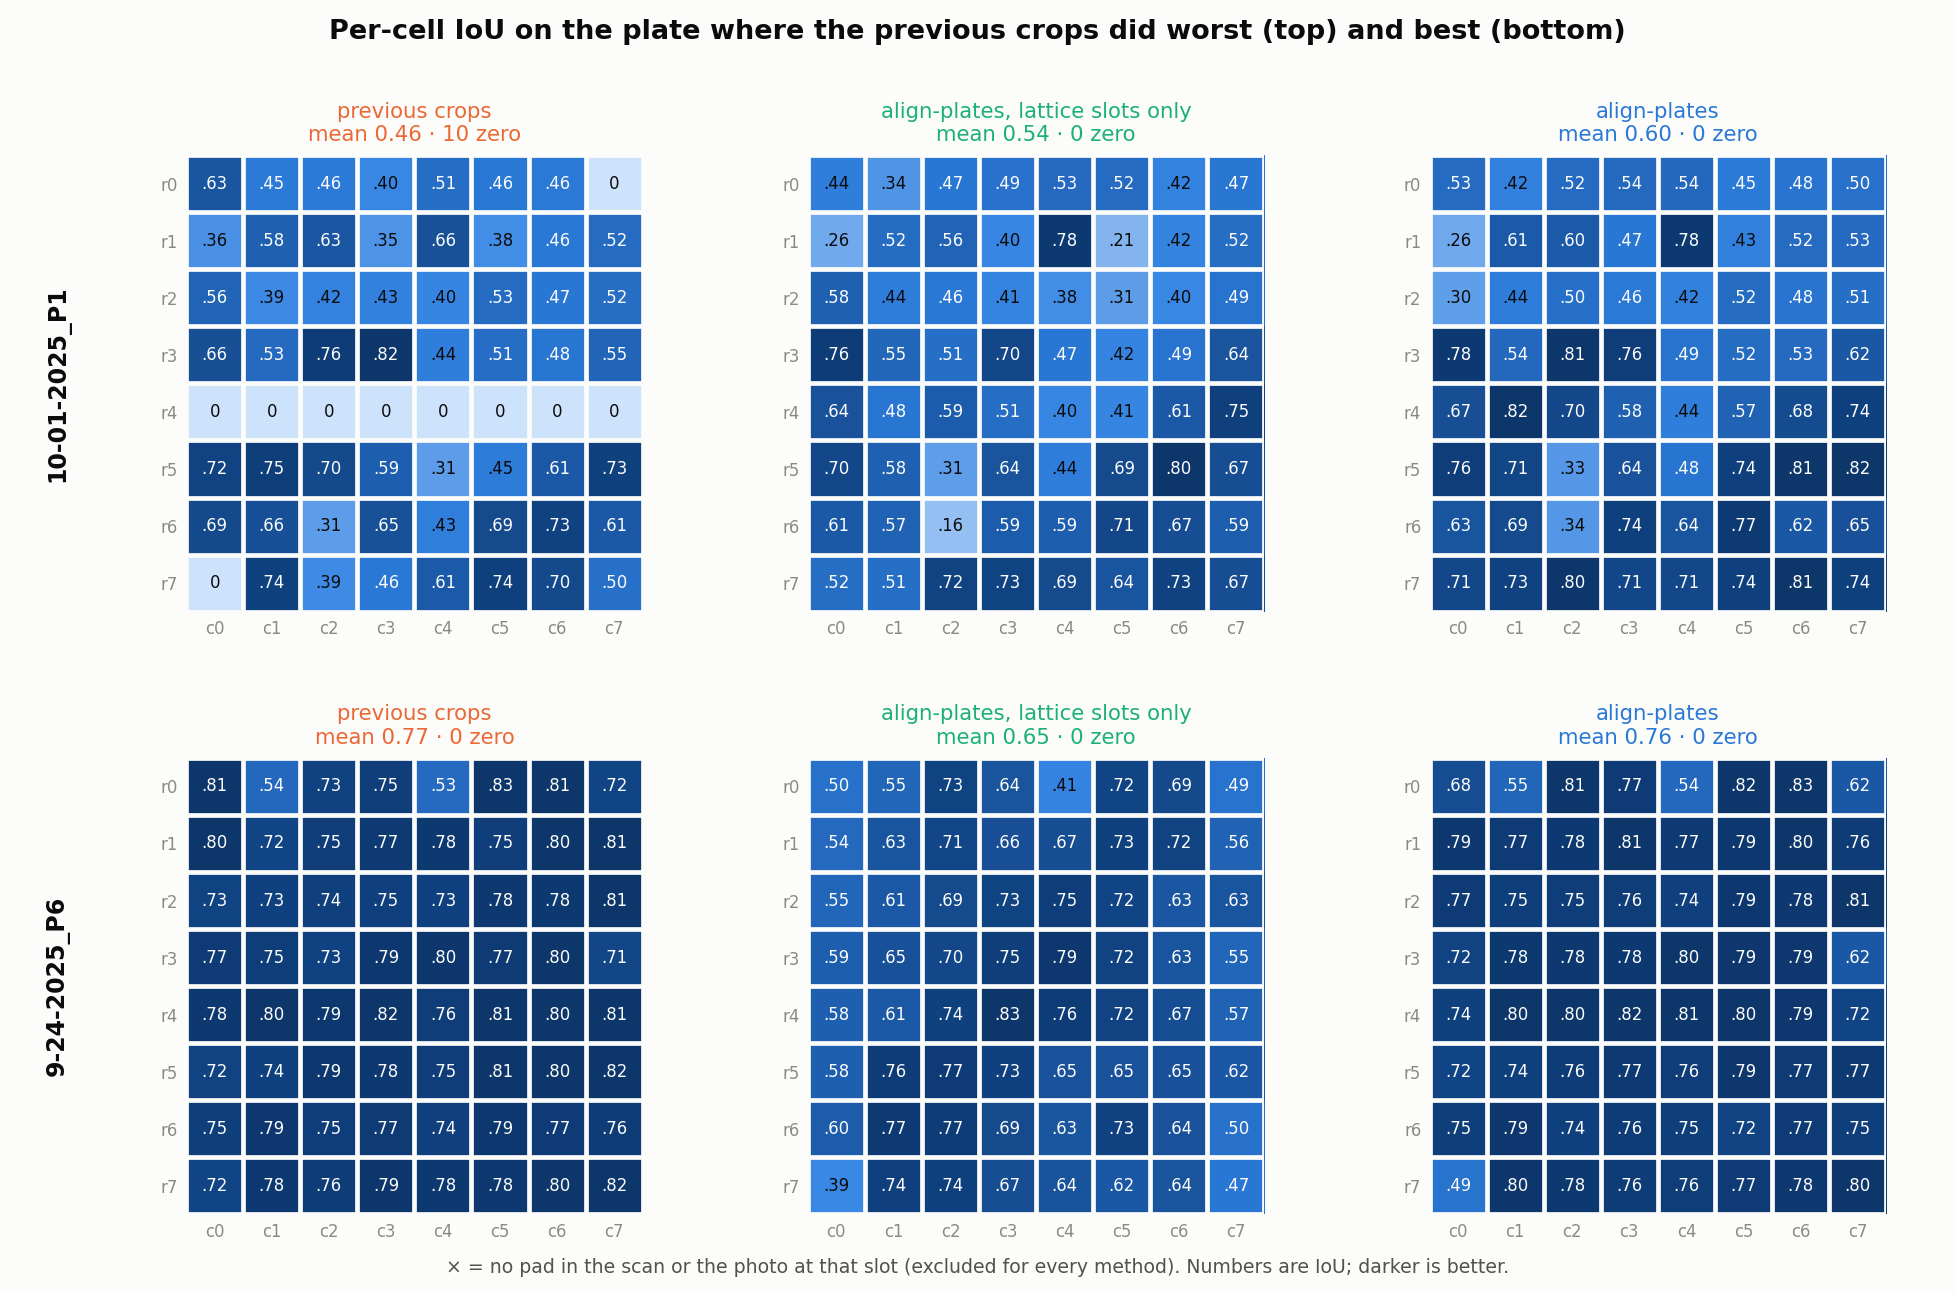

In [5]:
display(Image(str(STUDY / "figures" / "iou_plate_grid.png"), width=1000))

## 5. Why the ceiling is not 1

Even a perfect alignment cannot reach IoU = 1 here, because the two instruments
draw the pad differently. The stylus samples the scan every **30 µm along x**
(and 2.9 µm along y), so a 61 µm-wide pad is two or three samples wide and its
mask edge is smeared by interpolation; the photo resolves it at 1.25 µm. On top
of that the two instruments disagree about the grid's aspect ratio by ~4:3 (the
open calibration question from study 01), which stretches one mask relative to
the other. Sliding the masks so their centroids coincide gives the ceiling
reported in the table; the gap between a method's IoU and that ceiling is the
part that alignment is responsible for.

In [6]:
by_m = defaultdict(list)
for c in scored:
    if c["status"] == "ok":
        by_m[c["method"]].append((float(c["iou"]), float(c["ceiling_iou"])))
for m in L.METHODS:
    a = np.array(by_m[m])
    print(f"{L.METHOD_LABEL[m]:36} mean IoU {a[:,0].mean():.3f}   mean ceiling {a[:,1].mean():.3f}   "
          f"IoU/ceiling {np.mean(a[:,0]/np.maximum(a[:,1],1e-9)):.3f}")

previous crops                       mean IoU 0.683   mean ceiling 0.727   IoU/ceiling 0.939
align-plates, lattice slots only (as shipped 2026-10-08) mean IoU 0.634   mean ceiling 0.729   IoU/ceiling 0.873
align-plates (detected centres, current default) mean IoU 0.709   mean ceiling 0.729   IoU/ceiling 0.974


## 6. Converting the previous scan coordinates

The previous pipeline rotated and resampled the scan before locating pads, so
its centroids are in a space of unknown scale. Because both pipelines index
cells by (row, col), the mapping to micrometres is a six-parameter affine fit
on the matched cells, with 3-MAD rejection so the cells the previous pipeline
got wrong do not bend the conversion. The residual on the kept cells is the
check that the conversion is right.

In [7]:
r = np.array([float(c["rmse_um"]) for c in conv]); used = np.array([int(c["n_used"]) for c in conv]); tot = np.array([int(c["n_total"]) for c in conv])
print(f"affine residual on kept cells: median {np.median(r):.1f} µm, max {r.max():.1f} µm")
print(f"cells kept for the fit: {used.sum()} of {tot.sum()} ({100*used.sum()/tot.sum():.1f}%) — the rest are the previous pipeline's whole-pitch misses")
print(f"µm per unit: x {np.median([float(c['um_per_unit_x']) for c in conv]):.3f}, y {np.median([float(c['um_per_unit_y']) for c in conv]):.3f}")

affine residual on kept cells: median 2.9 µm, max 4.1 µm
cells kept for the fit: 2714 of 2789 (97.3%) — the rest are the previous pipeline's whole-pitch misses
µm per unit: x 4.555, y 6.914


## 7. Reproduce

```bash
uv run python studies/03-alignment-iou/src/compute_iou.py
uv run python studies/03-alignment-iou/src/make_figures.py
uv run python studies/03-alignment-iou/src/make_notebook.py --write
uv run python -m nbconvert --to notebook --execute --inplace studies/03-alignment-iou/iou.ipynb
```